In [83]:
# Section 10: Save Plots and Results
# Save the generated figures and metric summary for later review.
from pathlib import Path

out_dir = Path(r"C:\Users\danil\OneDrive\Projetos\ProjetoIA025\results\20261107_222543_u-net") / "visualization_report"
out_dir.mkdir(exist_ok=True, parents=True)

for idx, fig in enumerate(plt.get_fignums()):
    fig_obj = plt.figure(fig)
    fig_obj.savefig(out_dir / f"figure_{idx + 1}.png", dpi=200, bbox_inches="tight")

metrics_df.to_csv(out_dir / "metrics_summary.csv", index=False)
print(f"Figures and metrics saved to: {out_dir}")


Figures and metrics saved to: C:\Users\danil\OneDrive\Projetos\ProjetoIA025\results\20261107_222543_u-net\visualization_report


# Results Visualization Notebook
# Compare prediction, ground truth, and valid mask for the latest saved segmentation run.


In [72]:
# Section 1: Import Required Libraries
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

print('Libraries imported successfully.')


Libraries imported successfully.


In [73]:
# Section 2: Load Prediction and Ground Truth Data
# Choose which saved patch to inspect in the latest run.

repo_root = Path.cwd()
results_dir = repo_root / 'results'
if not results_dir.exists():
    raise FileNotFoundError(f'Results directory not found: {results_dir}')

run_dirs = sorted(results_dir.glob('*'))
latest_run = max([p for p in run_dirs if p.is_dir()], key=lambda p: p.stat().st_mtime, default=None)
if latest_run is None:
    raise FileNotFoundError('No run directories found under results/.')

prediction_dir = latest_run / 'predictions'
prediction_files = sorted(prediction_dir.glob('*.npz'))
if not prediction_files:
    raise FileNotFoundError(f'No prediction files found in: {prediction_dir}')

print(f'Using run directory: {latest_run}')
print('Available patches:')
for idx, path in enumerate(prediction_files):
    print(f'  [{idx}] {path.name}')

# Change this number to inspect a different patch from the list above.
# If there is only one file, keep it at 0.
patch_index = 1
if patch_index >= len(prediction_files):
    print(f'Warning: patch_index={patch_index} is out of range; using the last available patch instead.')
    patch_index = len(prediction_files) - 1

prediction_file = prediction_files[patch_index]

with np.load(prediction_file) as data:
    prediction = data['prediction']
    target = data['target']
    valid = data['valid']
    name = str(data['name']) if 'name' in data.files else prediction_file.stem

print(f'Selected patch: {prediction_file.name}')
print(f'Prediction shape: {prediction.shape}, dtype={prediction.dtype}')
print(f'Target shape: {target.shape}, dtype={target.dtype}')
print(f'Valid mask shape: {valid.shape}, dtype={valid.dtype}')
print(f'Example name: {name}')


Using run directory: c:\Users\danil\OneDrive\Projetos\ProjetoIA025\results\20261107_222543_u-net
Available patches:
  [0] 20130107_y0000_x0256_prediction.npz
  [1] 20130107_y0000_x0768_prediction.npz
  [2] 20130107_y0256_x0512_prediction.npz
  [3] 20130107_y1280_x1024_prediction.npz
Selected patch: 20130107_y0000_x0768_prediction.npz
Prediction shape: (256, 256), dtype=float32
Target shape: (256, 256), dtype=float32
Valid mask shape: (256, 256), dtype=float32
Example name: 20130107_y0000_x0768.npz


In [74]:
# Section 3: Prepare and Align Arrays
# Ensure all arrays are in the same format and valid region is applied.

prediction = np.asarray(prediction, dtype=np.float32)
target = np.asarray(target, dtype=np.float32)
valid = np.asarray(valid, dtype=np.float32)

if prediction.ndim == 3:
    prediction = prediction[..., 0]
if target.ndim == 3:
    target = target[..., 0]
if valid.ndim == 3:
    valid = valid[..., 0]

prediction = (prediction > 0.5).astype(np.float32)
target = (target > 0.5).astype(np.float32)
valid = (valid > 0.5).astype(np.float32)

prediction = prediction * valid
target = target * valid

print('Aligned arrays:')
print(f' prediction: {prediction.shape}, min={prediction.min()}, max={prediction.max()}')
print(f' target: {target.shape}, min={target.min()}, max={target.max()}')
print(f' valid: {valid.shape}, min={valid.min()}, max={valid.max()}')


Aligned arrays:
 prediction: (256, 256), min=0.0, max=1.0
 target: (256, 256), min=0.0, max=1.0
 valid: (256, 256), min=0.0, max=1.0


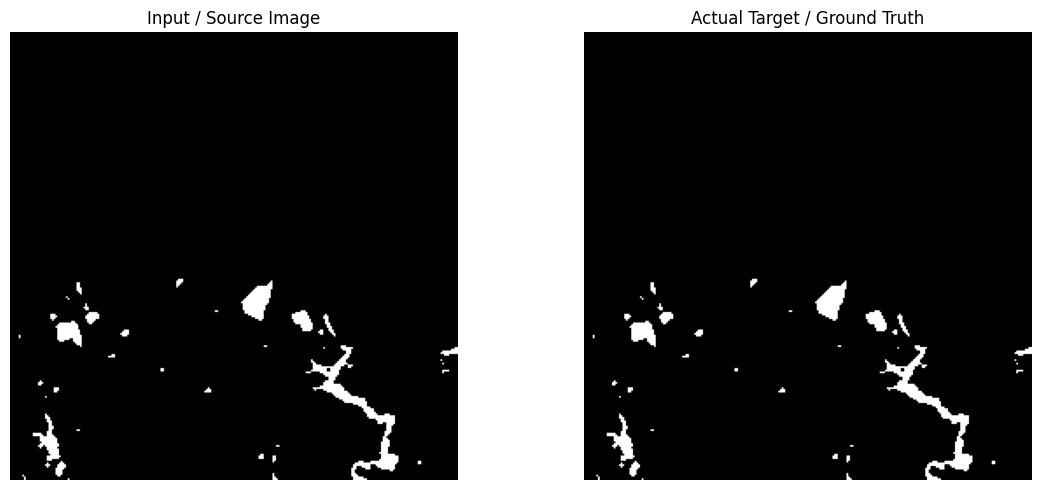

In [75]:
# Section 4: Visualize Input Image with Actual Target
# Show the input image and actual target for comparison baseline.

source_image = None
if 'source' in locals() and source_image is not None:
    image_to_show = source_image
else:
    image_to_show = target

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_to_show, cmap='gray' if image_to_show.ndim == 2 else None)
axes[0].set_title('Input / Source Image')
axes[0].axis('off')

axes[1].imshow(target, cmap='gray')
axes[1].set_title('Actual Target / Ground Truth')
axes[1].axis('off')

plt.tight_layout()
plt.show()


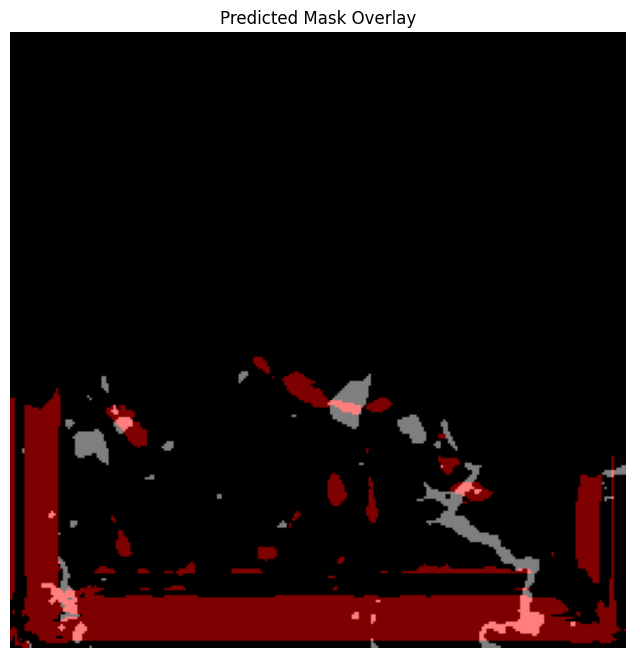

In [76]:
# Section 5: Overlay Predicted Mask on Input Image
# Overlay prediction in red on the source image or target field.

if image_to_show.ndim == 2:
    base = image_to_show.copy()
else:
    base = image_to_show[..., 0].copy()

rgb = np.stack([base, base, base], axis=-1)
if rgb.max() <= 1.0:
    rgb = rgb * 255.0
rgb = rgb.astype(np.float32)

mask_rgb = np.zeros_like(rgb, dtype=np.float32)
mask_rgb[..., 0] = 255.0 * prediction
mask_rgb[..., 1] = 0.0
mask_rgb[..., 2] = 0.0

alpha = 0.5
overlay = rgb * (1 - alpha) + mask_rgb * alpha

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(overlay.astype(np.uint8))
ax.set_title('Predicted Mask Overlay')
ax.axis('off')
plt.show()


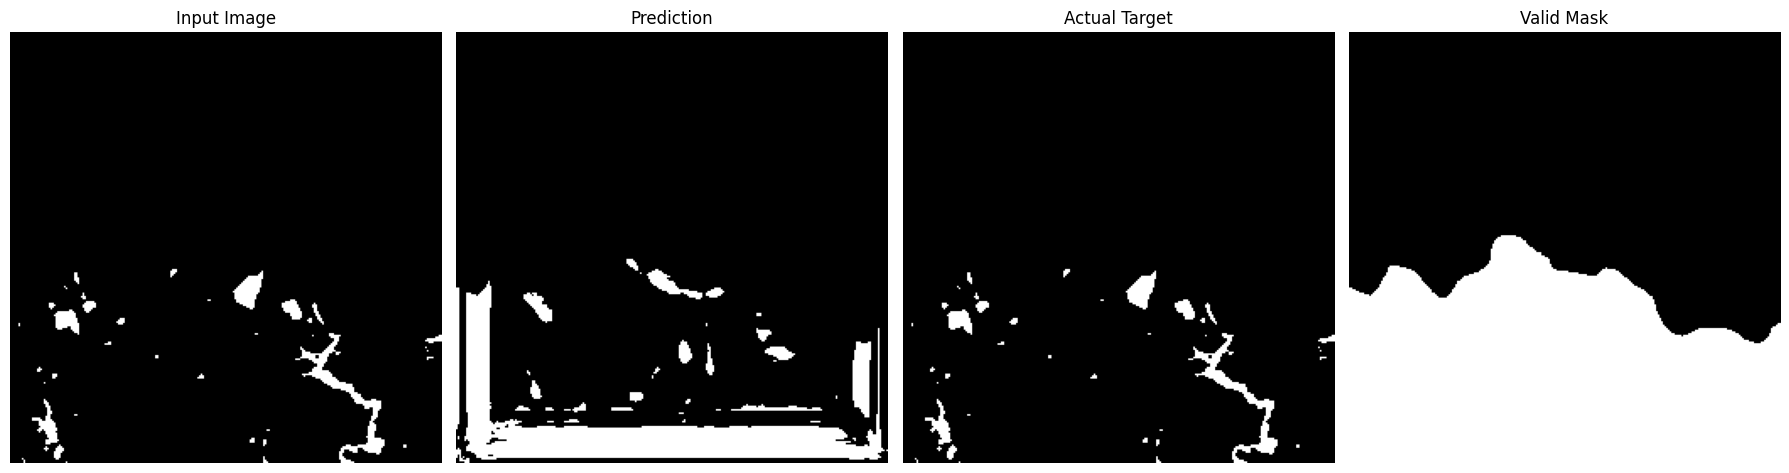

In [77]:
# Section 6: Compare Prediction and Actual Side-by-Side
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_to_show, cmap='gray' if np.asarray(image_to_show).ndim == 2 else None)
axes[0].set_title('Input Image')
axes[0].axis('off')

axes[1].imshow(prediction, cmap='gray')
axes[1].set_title('Prediction')
axes[1].axis('off')

axes[2].imshow(target, cmap='gray')
axes[2].set_title('Actual Target')
axes[2].axis('off')

axes[3].imshow(valid, cmap='gray')
axes[3].set_title('Valid Mask')
axes[3].axis('off')

plt.tight_layout()
plt.show()


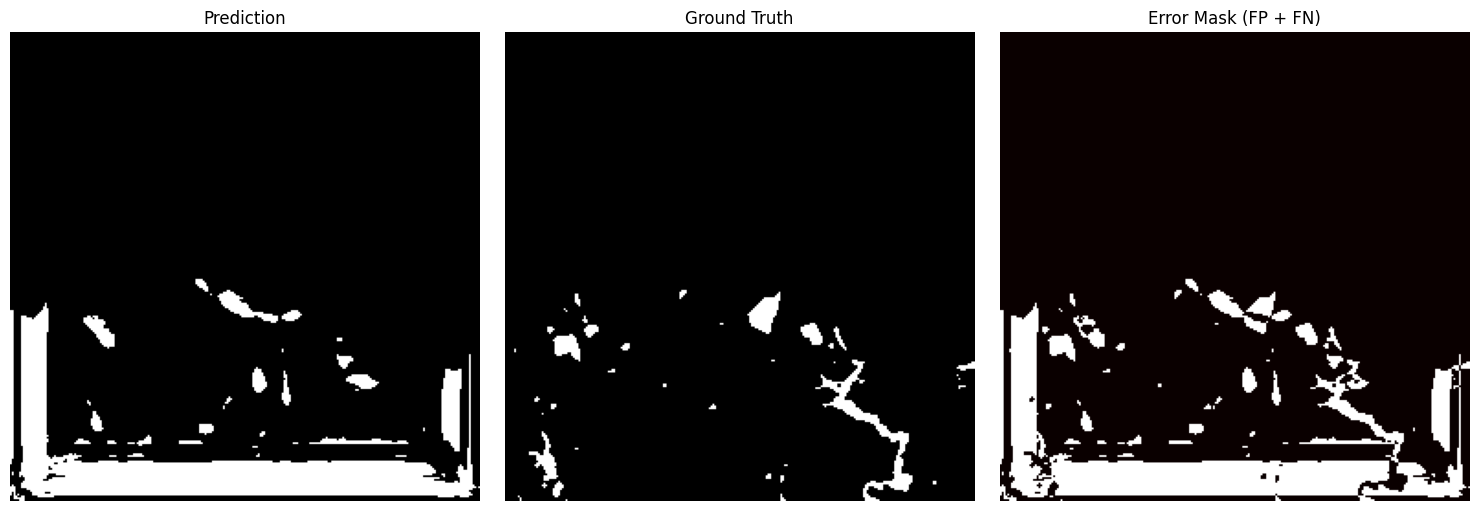

In [78]:
# Section 7: Highlight Difference and Error Mask
# Compute false positives and false negatives to highlight the error mask.

difference = prediction - target
false_positive = np.logical_and(prediction == 1, target == 0).astype(np.float32)
false_negative = np.logical_and(prediction == 0, target == 1).astype(np.float32)
error_mask = false_positive + false_negative

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(prediction, cmap='gray')
axes[0].set_title('Prediction')
axes[0].axis('off')

axes[1].imshow(target, cmap='gray')
axes[1].set_title('Ground Truth')
axes[1].axis('off')

axes[2].imshow(error_mask, cmap='hot')
axes[2].set_title('Error Mask (FP + FN)')
axes[2].axis('off')

plt.tight_layout()
plt.show()


In [79]:
# Section 8: Compute Evaluation Metrics
# Compute segmentation metrics from the prediction and target mask.

def compute_iou(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    union = np.logical_or(pred, true).sum()
    return float(intersection / union) if union > 0 else 0.0


def compute_dice(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    return float((2 * intersection) / (pred.sum() + true.sum())) if (pred.sum() + true.sum()) > 0 else 0.0


def compute_accuracy(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    return float(np.mean(pred == true))


def compute_precision(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    tp = np.logical_and(pred, true).sum()
    fp = np.logical_and(pred, np.logical_not(true)).sum()
    return float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0


def compute_recall(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    tp = np.logical_and(pred, true).sum()
    fn = np.logical_and(np.logical_not(pred), true).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0


def compute_f1(pred, true):
    precision = compute_precision(pred, true)
    recall = compute_recall(pred, true)
    return float(2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

metrics = {
    'IoU': compute_iou(prediction, target),
    'Dice': compute_dice(prediction, target),
    'Accuracy': compute_accuracy(prediction, target),
    'Precision': compute_precision(prediction, target),
    'Recall': compute_recall(prediction, target),
    'F1': compute_f1(prediction, target),
}

print('Segmentation Metrics:')
for k, v in metrics.items():
    print(f'  {k}: {v:.4f}')

metrics_df = pd.DataFrame([metrics])
metrics_df


Segmentation Metrics:
  IoU: 0.0556
  Dice: 0.1053
  Accuracy: 0.8797
  Precision: 0.0638
  Recall: 0.3023
  F1: 0.1053


,IoU,Dice,Accuracy,Precision,Recall,F1
0,0.055602,0.105347,0.879745,0.063789,0.30228,0.105347


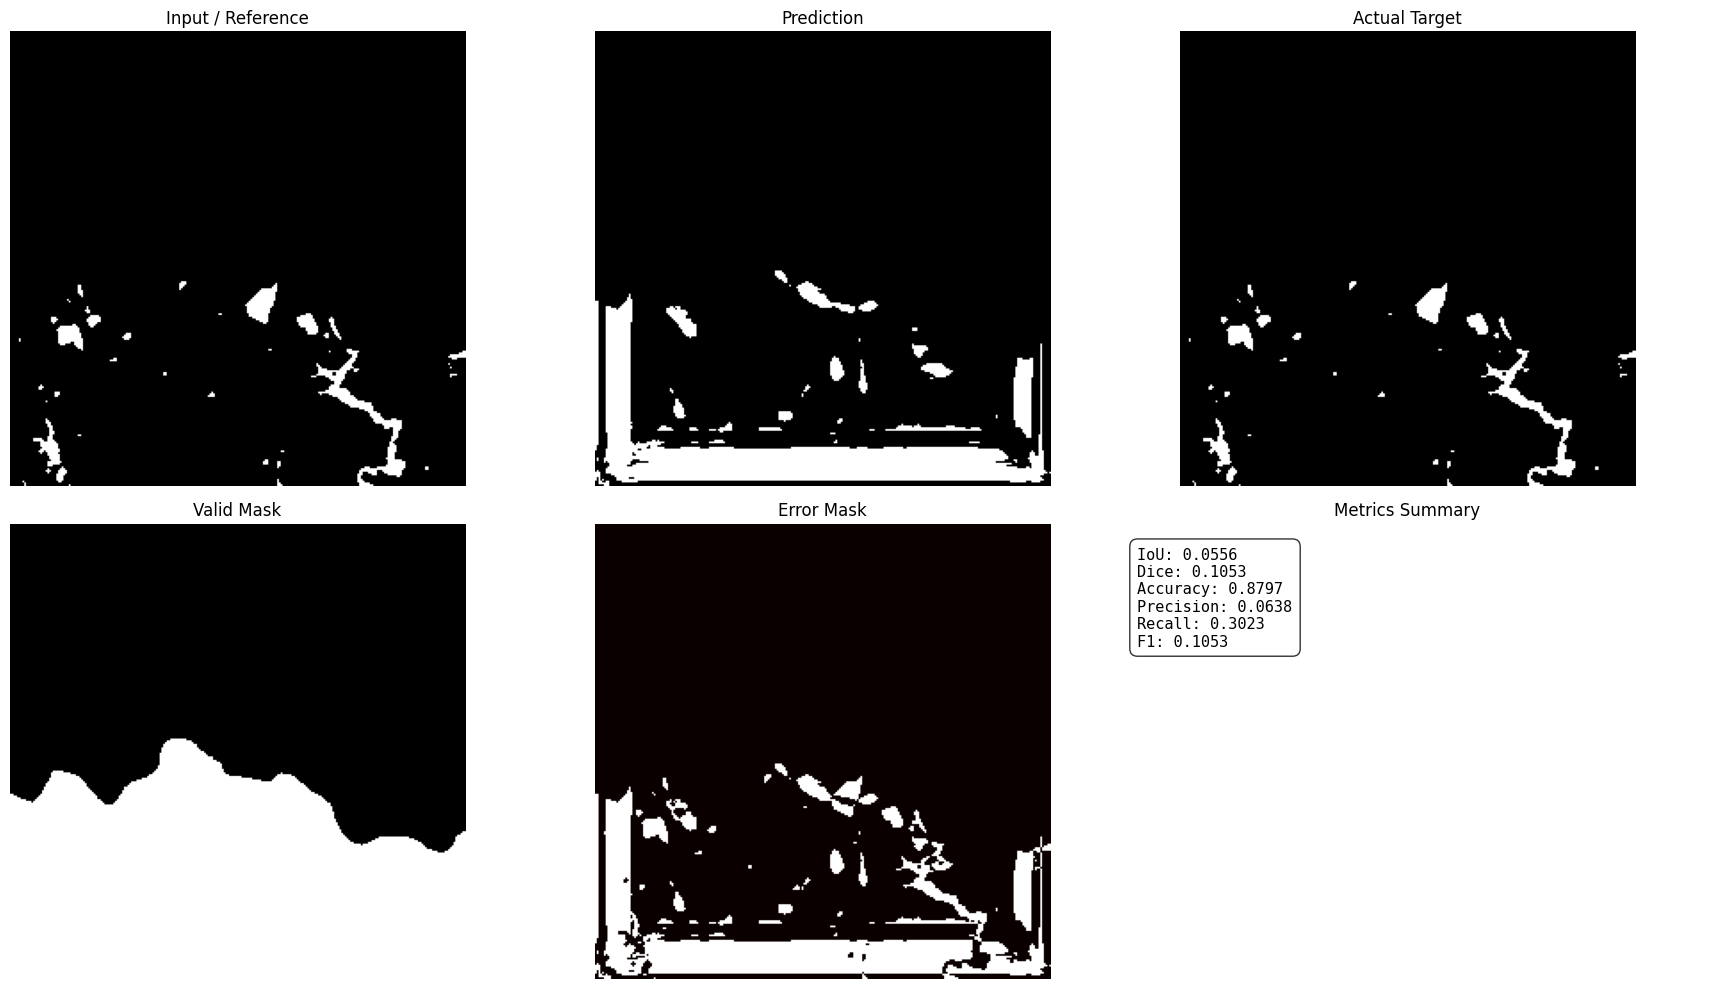

In [80]:
# Section 9: Create Summary Visualization Dashboard
# Build a compact report with the main comparison and metric values.

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(image_to_show, cmap='gray')
axes[0, 0].set_title('Input / Reference')
axes[0, 0].axis('off')

axes[0, 1].imshow(prediction, cmap='gray')
axes[0, 1].set_title('Prediction')
axes[0, 1].axis('off')

axes[0, 2].imshow(target, cmap='gray')
axes[0, 2].set_title('Actual Target')
axes[0, 2].axis('off')

axes[1, 0].imshow(valid, cmap='gray')
axes[1, 0].set_title('Valid Mask')
axes[1, 0].axis('off')

axes[1, 1].imshow(error_mask, cmap='hot')
axes[1, 1].set_title('Error Mask')
axes[1, 1].axis('off')

axes[1, 2].axis('off')
text = '\n'.join(f'{k}: {v:.4f}' for k, v in metrics.items())
axes[1, 2].text(0.05, 0.95, text, va='top', fontsize=11, family='monospace', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))
axes[1, 2].set_title('Metrics Summary')

plt.tight_layout()
plt.show()


In [84]:
import re
from pathlib import Path
import numpy as np

def parse_patch_pos(path):
    name = Path(path).stem
    m = re.search(r"_y(\d+)_x(\d+)$", name)
    if not m:
        raise ValueError(f"Bad patch name: {path}")
    return int(m.group(1)), int(m.group(2))

patch_dir = Path("DATASET_UNET/DATASET_UNET/patches")
patch_files = sorted(patch_dir.glob("*.npz"))

date_prefix = "20130107"   # choose one date
selected = [p for p in patch_files if p.name.startswith(date_prefix)]

if not selected:
    raise FileNotFoundError(f"No patches for date {date_prefix}")

coords = [parse_patch_pos(p) for p in selected]
ys = [y for y, _ in coords]
xs = [x for _, x in coords]

patch_size = 256
full_y = max(y + patch_size for y in ys)
full_x = max(x + patch_size for x in xs)

full_target = np.zeros((full_y, full_x), dtype=np.float32)
full_valid = np.zeros_like(full_target)

for p in selected:
    y0, x0 = parse_patch_pos(p)
    with np.load(p, allow_pickle=False) as d:
        target = d["y"]
        valid = d["valido"]
    y1 = y0 + target.shape[0]
    x1 = x0 + target.shape[1]
    full_target[y0:y1, x0:x1] = target
    full_valid[y0:y1, x0:x1] = valid

print("date map shape:", full_target.shape)
print("flood pixels:", int(np.count_nonzero(full_target)))
print("valid pixels:", int(np.count_nonzero(full_valid)))

date map shape: (1867, 1417)
flood pixels: 48255
valid pixels: 1125431


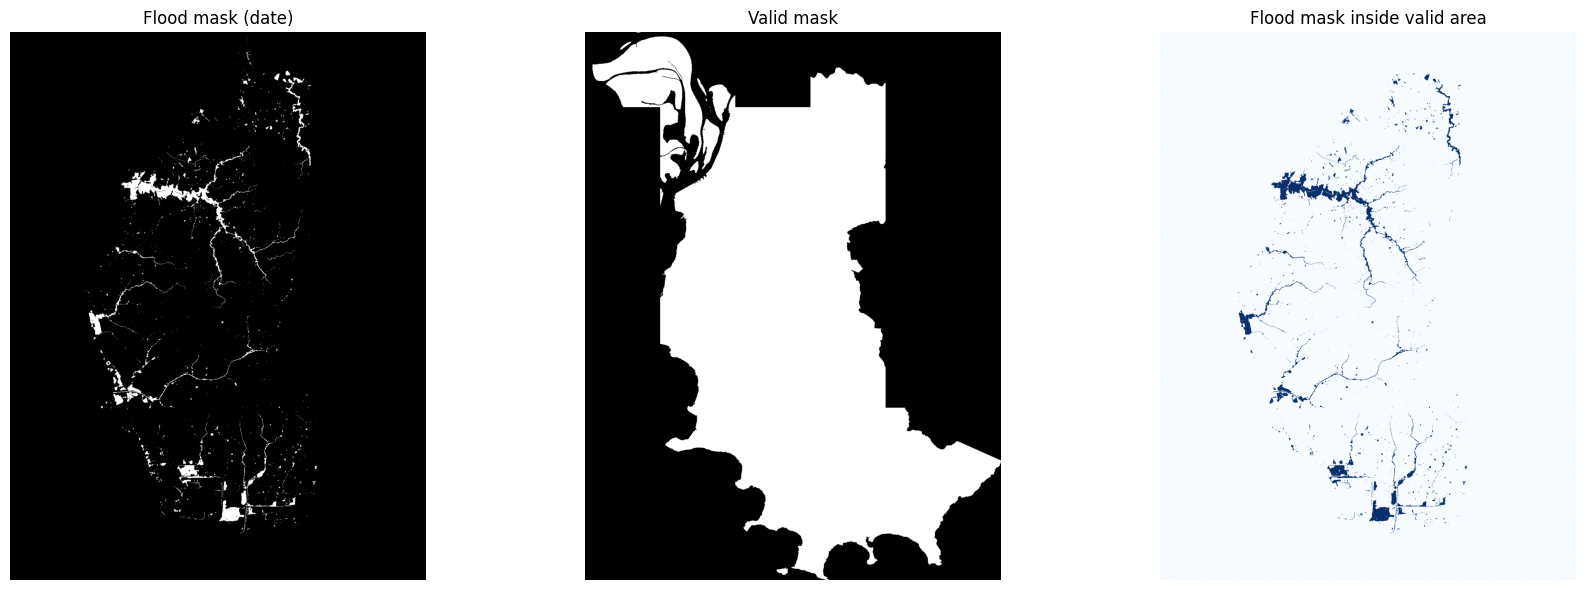

In [85]:
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def parse_patch_pos(path):
    name = Path(path).stem
    m = re.search(r"_y(\d+)_x(\d+)$", name)
    if not m:
        raise ValueError(f"Bad patch name: {path}")
    return int(m.group(1)), int(m.group(2))

patch_dir = Path("DATASET_UNET/DATASET_UNET/patches")
patch_files = sorted(patch_dir.glob("*.npz"))

date_prefix = "20130107"   # pick one date
selected = [p for p in patch_files if p.name.startswith(date_prefix)]

if not selected:
    raise FileNotFoundError(f"No patches for {date_prefix}")

coords = [parse_patch_pos(p) for p in selected]
ys = [y for y, _ in coords]
xs = [x for _, x in coords]

patch_size = 256
full_y = max(y + patch_size for y in ys)
full_x = max(x + patch_size for x in xs)

full_target = np.zeros((full_y, full_x), dtype=np.float32)
full_valid = np.zeros_like(full_target)

for p in selected:
    y0, x0 = parse_patch_pos(p)
    with np.load(p, allow_pickle=False) as d:
        target = np.asarray(d["y"], dtype=np.float32)
        valid = np.asarray(d["valido"], dtype=np.float32)

    y1 = y0 + target.shape[0]
    x1 = x0 + target.shape[1]
    full_target[y0:y1, x0:x1] = target
    full_valid[y0:y1, x0:x1] = valid

# valid-only target for plotting
masked = np.where(full_valid > 0, full_target, 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(full_target, cmap="gray")
axes[0].set_title("Flood mask (date)")
axes[1].imshow(full_valid, cmap="gray")
axes[1].set_title("Valid mask")
axes[2].imshow(masked, cmap="Blues")
axes[2].set_title("Flood mask inside valid area")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

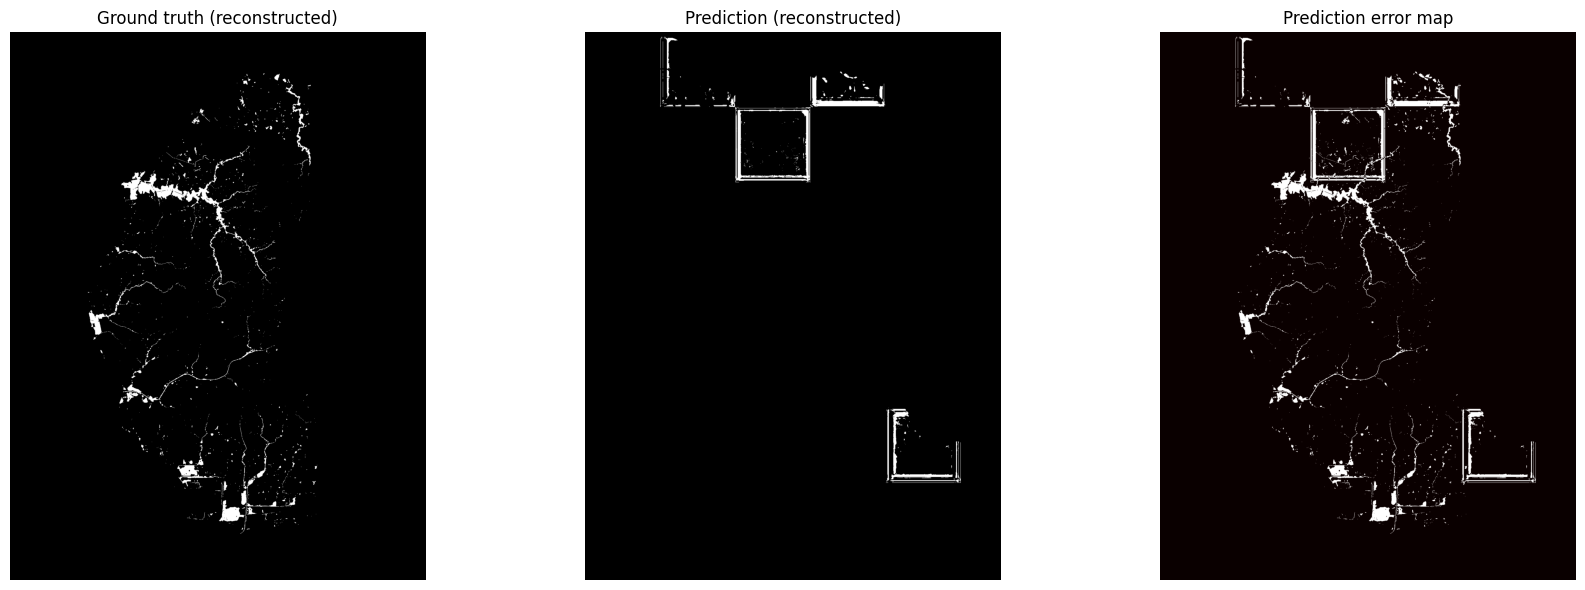

In [ ]:
# Section 4b: Reconstruct the full map for one date and compare truth vs prediction
# This is the proper visualization for a patch-based dataset: one date = one full city map.

def parse_patch_name_position(name: str):
    match = re.search(r"_y(\d+)_x(\d+)", name)
    if match is None:
        raise ValueError(f"Patch name does not contain a tile position: {name}")
    return int(match.group(1)), int(match.group(2))


def reconstruct_date_map(date_prefix: str, patch_paths):
    selected = [p for p in patch_paths if p.name.startswith(date_prefix)]
    if not selected:
        raise FileNotFoundError(f"No dataset patches for date {date_prefix}")

    coords = [parse_patch_name_position(p.name) for p in selected]
    y0s = [y for y, _ in coords]
    x0s = [x for _, x in coords]
    patch_size = 256
    full_y = max(y + patch_size for y in y0s)
    full_x = max(x + patch_size for x in x0s)

    target_map = np.zeros((full_y, full_x), dtype=np.float32)
    valid_map = np.zeros_like(target_map)

    for p in selected:
        y0, x0 = parse_patch_name_position(p.name)
        with np.load(p, allow_pickle=False) as d:
            target = np.asarray(d["y"], dtype=np.float32)
            valid = np.asarray(d["valido"], dtype=np.float32)
        y1 = y0 + target.shape[0]
        x1 = x0 + target.shape[1]
        target_map[y0:y1, x0:x1] = target
        valid_map[y0:y1, x0:x1] = valid

    return target_map, valid_map


def reconstruct_prediction_map(date_prefix: str, prediction_paths):
    selected = []
    for p in prediction_paths:
        if re.search(rf"^{re.escape(date_prefix)}_y\d+_x\d+.*", p.name):
            selected.append(p)
    if not selected:
        raise FileNotFoundError(f"No prediction files for date {date_prefix}")

    coords = [parse_patch_name_position(p.name.replace("_prediction.npz", ".npz")) for p in selected]
    y0s = [y for y, _ in coords]
    x0s = [x for _, x in coords]
    patch_size = 256
    full_y = max(y + patch_size for y in y0s)
    full_x = max(x + patch_size for x in x0s)

    pred_map = np.zeros((full_y, full_x), dtype=np.float32)
    for p in selected:
        y0, x0 = parse_patch_name_position(p.name.replace("_prediction.npz", ".npz"))
        with np.load(p, allow_pickle=False) as d:
            pred = np.asarray(d["prediction"], dtype=np.float32)
        if pred.ndim == 3:
            pred = pred[..., 0]
        pred = (pred > 0.5).astype(np.float32)
        y1 = y0 + pred.shape[0]
        x1 = x0 + pred.shape[1]
        pred_map[y0:y1, x0:x1] = pred
    return pred_map

# Choose one available date to inspect.
all_dataset_patches = sorted(Path("DATASET_UNET/DATASET_UNET/patches").glob("*.npz"))
available_dates = sorted({p.name.split("_y")[0] for p in all_dataset_patches})
print("Available dates:", available_dates[:10])
date_prefix = available_dates[0]

# Build the maps for that date.
target_map, valid_map = reconstruct_date_map(date_prefix, all_dataset_patches)
pred_map = reconstruct_prediction_map(date_prefix, prediction_files)

masked_target = np.where(valid_map > 0, target_map, 0.0)
masked_prediction = np.where(valid_map > 0, pred_map, 0.0)
error_map = np.where(valid_map > 0, (pred_map != target_map).astype(np.float32), 0.0)

# Display the big map view.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(masked_target, cmap="gray")
axes[0].set_title(f"Ground truth ({date_prefix})")
axes[0].axis("off")

axes[1].imshow(masked_prediction, cmap="gray")
axes[1].set_title(f"Prediction ({date_prefix})")
axes[1].axis("off")

axes[2].imshow(error_map, cmap="hot")
axes[2].set_title("Error map")
axes[2].axis("off")

plt.tight_layout()
plt.show()
